# Week 1

no code yet for week 1, still working on the project proposal

# Week 2

Finding and vetting the data. Checking the OULAD files myself before I trust anything in them.

Just using the csv module here. The files are big but it still runs in a few seconds.

In [1]:
# load up studentInfo, thats the main one with a row per student per course
import csv

f = open("Week 1/data/studentInfo.csv")
reader = csv.DictReader(f)
students = []
for row in reader:
    students.append(row)
f.close()

print("studentInfo rows:", len(students))
print("the docs that come with the data say 32953, so the docs are wrong")

# what happened to everyone
counts = {}
for s in students:
    r = s["final_result"]
    if r in counts:
        counts[r] = counts[r] + 1
    else:
        counts[r] = 1

print()
print("final result counts:")
for k in counts:
    print(" ", k, counts[k])

studentInfo rows: 32593
the docs that come with the data say 32953, so the docs are wrong

final result counts:
  Pass 12361
  Withdrawn 10156
  Fail 7052
  Distinction 3024


Missing values are written as a `?` instead of being left blank. So if you load this normally the column still looks fine but its actually text, and checking for missing values comes back with nothing.

In [2]:
# count the ? ones
qmark = 0
for s in students:
    if s["imd_band"] == "?":
        qmark = qmark + 1

print("imd_band missing (written as ?):", qmark)
print("percent:", round(qmark / len(students) * 100, 2))

# also one of the labels is broken, every band ends in % except one
bands = {}
for s in students:
    b = s["imd_band"]
    if b in bands:
        bands[b] = bands[b] + 1
    else:
        bands[b] = 1

print()
print("the bands i found:")
for k in bands:
    print(" ", repr(k), bands[k])

imd_band missing (written as ?): 1111
percent: 3.41

the bands i found:
  '90-100%' 2536
  '20-30%' 3654
  '30-40%' 3539
  '50-60%' 3124
  '80-90%' 2762
  '70-80%' 2879
  '?' 1111
  '60-70%' 2905
  '40-50%' 3256
  '10-20' 3516
  '0-10%' 3311


`'10-20'` has no percent sign so it reads as a separate eleventh category. 3,516 students.

Next question, is the missing imd_band random? Because if it is I could just fill it in.

In [3]:
# do students with no imd band do better or worse
miss_pass = 0
miss_tot = 0
have_pass = 0
have_tot = 0
for s in students:
    passed = 0
    if s["final_result"] == "Pass":
        passed = 1
    if s["imd_band"] == "?":
        miss_tot = miss_tot + 1
        miss_pass = miss_pass + passed
    else:
        have_tot = have_tot + 1
        have_pass = have_pass + passed

print("pass rate when imd_band is missing:", round(miss_pass / miss_tot * 100, 1))
print("pass rate when we have it:", round(have_pass / have_tot * 100, 1))
print()
print("so its not random. filling it with the most common band would wipe out a real signal")

pass rate when imd_band is missing: 47.8
pass rate when we have it: 37.6

so its not random. filling it with the most common band would wipe out a real signal


Now the big one. My whole idea is to flag students early enough for a tutor to reach them, so I need to know **when** people actually withdraw.

In [4]:
# get the unregistration dates
f = open("Week 1/data/studentRegistration.csv")
reader = csv.DictReader(f)
reg = {}
for row in reader:
    key = row["code_module"] + "-" + row["code_presentation"] + "-" + row["id_student"]
    reg[key] = row["date_unregistration"]
f.close()

print("registration rows:", len(reg))

# day 0 is the first day of the course, negative means before it started
cut = 28
before = 0
after = 0
nodate = 0
for s in students:
    if s["final_result"] != "Withdrawn":
        continue
    key = s["code_module"] + "-" + s["code_presentation"] + "-" + s["id_student"]
    d = reg[key]
    if d == "?":
        nodate = nodate + 1
    else:
        if int(d) < cut:
            before = before + 1
        else:
            after = after + 1

print()
print("of the students who withdrew:")
print("  already gone before day", cut, ":", before)
print("  left after day", cut, ":", after)
print("  no date at all:", nodate)
print()
print(round(before / (before + after + nodate) * 100, 1), "percent had already left before my cutoff")

registration rows: 32593

of the students who withdrew:
  already gone before day 28 : 5032
  left after day 28 : 5031
  no date at all: 93

49.5 percent had already left before my cutoff


This is the thing that changes the project. Half of them are already gone by day 28.

I cant predict a student who already left. If I leave them in, the model learns that a student with no clicks withdrew, which is true but backwards, they had no clicks because they were already gone. So I drop them.

In [5]:
# drop anyone who already unregistered before the cutoff
keep = 0
keep_withdrew = 0
for s in students:
    key = s["code_module"] + "-" + s["code_presentation"] + "-" + s["id_student"]
    d = reg[key]
    w = 0
    if s["final_result"] == "Withdrawn":
        w = 1
    if d != "?" and int(d) < cut:
        continue
    # also drop the withdrawn ones with no date, cant place them in time
    if w == 1 and d == "?":
        continue
    keep = keep + 1
    keep_withdrew = keep_withdrew + w

print("started with:", len(students))
print("rows i can actually predict on:", keep)
print("of those, withdrew later:", keep_withdrew)
print("base rate:", round(keep_withdrew / keep * 100, 2), "percent")

started with: 32593
rows i can actually predict on: 27460
of those, withdrew later: 5031
base rate: 18.32 percent


Last check. The clickstream file is 10 million rows, and I want to know how many students never show up in it at all.

In [6]:
# this one takes a few seconds, its a big file
f = open("Week 1/data/studentVle.csv")
reader = csv.reader(f)
head = next(reader)
seen = {}
n = 0
for row in reader:
    n = n + 1
    key = row[0] + "-" + row[1] + "-" + row[2]
    seen[key] = 1
f.close()

print("clickstream rows:", n)
print("students who clicked at least once:", len(seen))

never = 0
never_withdrew = 0
for s in students:
    key = s["code_module"] + "-" + s["code_presentation"] + "-" + s["id_student"]
    if key not in seen:
        never = never + 1
        if s["final_result"] == "Withdrawn":
            never_withdrew = never_withdrew + 1

print()
print("students with no clicks at all:", never)
print("of those, withdrew:", never_withdrew, "which is", round(never_withdrew / never * 100, 1), "percent")
print("so i cant drop them, thats mostly the group im trying to find")

clickstream rows: 10655280
students who clicked at least once: 29228

students with no clicks at all: 3365
of those, withdrew: 2988 which is 88.8 percent
so i cant drop them, thats mostly the group im trying to find


**What I found this week**

- The row counts in the documentation are wrong, 32,593 not 32,953
- Missing values are `?` not blank, which quietly turns date columns into text
- One imd_band label is missing its percent sign
- The missing imd_band is not random, those students pass more often, so I keep it as its own category
- Half of all withdrawals happen before day 28, and those have to come out or the model is just predicting the past
- After that filter I have 27,460 students and an 18.3 percent withdrawal rate
- 3,365 students never click anything and 89 percent of them withdraw, so they get filled with zero, not dropped

# Week 3

Finding the insight. Week 2 said the data can answer my question once the students who already left are filtered out. This week the question is, out of the things a tutor can actually see by day 28, what seperates the students who withdraw from the ones who stay.

Using pandas and matplotlib now, the csv module was fine for counting but I need groupbys and charts. Figures get saved to `Week 3/figures/`.

In [7]:
# week 3 - eda to insight
# question for this week: what actually seperates the students who withdraw
# from the ones who stay, out of the stuff a tutor can see by day 28

import pandas as pd
import matplotlib.pyplot as plt

cut = 28

# ---------- load the small files ----------
# the ? thing from week 2, have to pass na_values or dates come in as text

info = pd.read_csv("Week 1/data/studentInfo.csv", na_values=["?"])
reg = pd.read_csv("Week 1/data/studentRegistration.csv", na_values=["?"])
assess = pd.read_csv("Week 1/data/assessments.csv", na_values=["?"])
sub = pd.read_csv("Week 1/data/studentAssessment.csv", na_values=["?"])

print("studentInfo:", len(info))

# join on the 3 columns that make a student-course row
key = ["code_module", "code_presentation", "id_student"]
df = pd.merge(info, reg, on=key)
print("after joining registration:", len(df))

studentInfo: 32593
after joining registration: 32593


Same filter as week 2, drop anyone who unregistered before day 28. Everything below is on the 27,460 that are left.

In [8]:
# ---------- the eligibility filter from week 2 ----------
# drop anyone who already left before the cutoff, and the withdrawn ones with no date

gone = (df["date_unregistration"].notna()) & (df["date_unregistration"] < cut)
nodate = (df["final_result"] == "Withdrawn") & (df["date_unregistration"].isna())
df = df[~gone & ~nodate].copy()

df["withdrew"] = 0
df.loc[df["final_result"] == "Withdrawn", "withdrew"] = 1

print("eligible at day", cut, ":", len(df))
print("withdrew later:", df["withdrew"].sum())
print("base rate:", round(df["withdrew"].mean() * 100, 1), "percent")

eligible at day 28 : 27460
withdrew later: 5031
base rate: 18.3 percent


First, how much does the course itself matter. A lot, it turns out. CCC loses almost 30 percent and GGG under 8. This is a problem for later, a model could look good just by learning which course a student is in, so every check below I try to repeat inside each module.


withdrawal rate by module (eligible students only):
  AAA 13.4 percent of 718
  BBB 14.0 percent of 6421
  CCC 29.6 percent of 3495
  DDD 23.7 percent of 5269
  EEE 13.2 percent of 2549
  FFF 18.5 percent of 6573
  GGG 7.9 percent of 2435


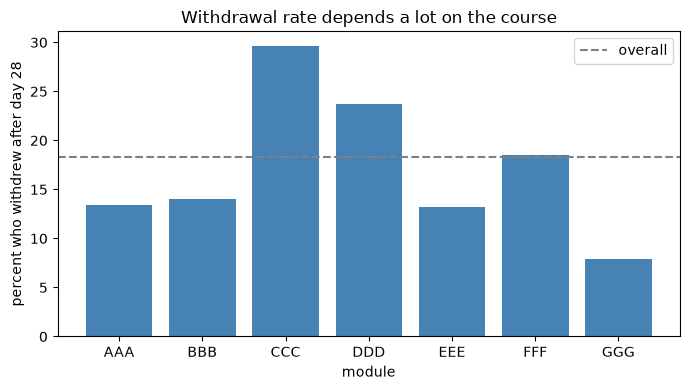

In [9]:
# ---------- 1. withdrawal rate by module ----------

print()
print("withdrawal rate by module (eligible students only):")
mod_rate = df.groupby("code_module")["withdrew"].mean() * 100
mod_n = df.groupby("code_module")["withdrew"].count()
for m in mod_rate.index:
    print(" ", m, round(mod_rate[m], 1), "percent of", mod_n[m])

plt.figure(figsize=(7, 4))
plt.bar(mod_rate.index, mod_rate.values, color="steelblue")
plt.axhline(df["withdrew"].mean() * 100, color="gray", linestyle="--", label="overall")
plt.ylabel("percent who withdrew after day 28")
plt.xlabel("module")
plt.title("Withdrawal rate depends a lot on the course")
plt.legend()
plt.tight_layout()
plt.savefig("Week 3/figures/fig1_module_rate.png", dpi=150)
plt.show()

Now the thing I actually want to know. 16 of the 22 course runs have an assignment due before day 28. For the students in those runs, did handing it in (or not) tell me anything?

Have to check the submitted date and not just the due date, otherwise I'm using submissions that happened after my cutoff.


assessments due before day 28 : 17
module-presentations with something due: 16 out of 22
students with an assignment due by day 28 : 22476

of those 22476 students:
  submitted something: 20001 withdrew 17.7 percent
  submitted nothing:   2475 withdrew 38.6 percent
  ratio: 2.2 times more likely

the no-submit list is 11.0 percent of the class
and it contains 21.2 percent of everyone who later withdrew


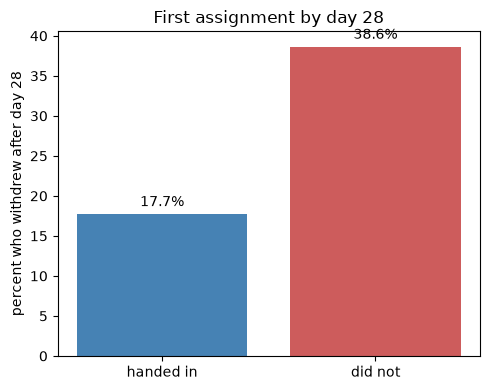


same split inside each module:
  AAA handed in 12.0  did not 30.2  n = 718
  BBB handed in 12.6  did not 27.0  n = 6421
  CCC handed in 27.3  did not 48.6  n = 3495
  DDD handed in 20.4  did not 45.5  n = 5269
  FFF handed in 16.2  did not 37.4  n = 6573


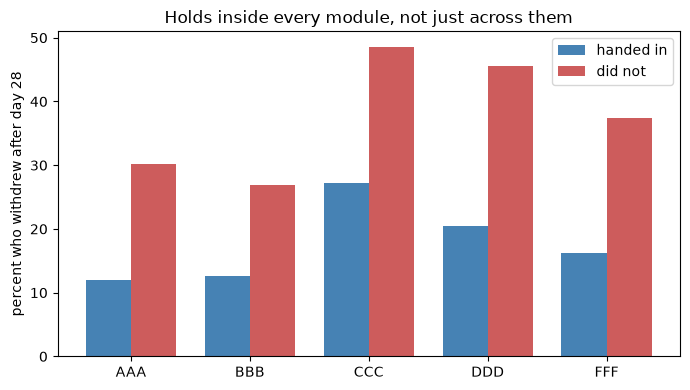

In [10]:
# ---------- 2. the first assignment ----------
# which module-presentations have something due before the cutoff

early = assess[assess["date"] < cut]
print()
print("assessments due before day", cut, ":", len(early))
has_due = early[["code_module", "code_presentation"]].drop_duplicates()
print("module-presentations with something due:", len(has_due), "out of",
      len(assess[["code_module", "code_presentation"]].drop_duplicates()))

# only look at students who actually had something due, otherwise its not fair
df = pd.merge(df, has_due.assign(had_due=1), on=["code_module", "code_presentation"], how="left")
df["had_due"] = df["had_due"].fillna(0)
print("students with an assignment due by day", cut, ":", int(df["had_due"].sum()))

# did they hand it in before the cutoff. have to check submitted date too,
# not just due date, or im peeking at the future
# studentAssessment doesnt have the module columns, they come through assessments
early_sub = pd.merge(sub, early[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
early_sub = early_sub[early_sub["date_submitted"] < cut]
who = early_sub[["code_module", "code_presentation", "id_student"]].drop_duplicates()
who["submitted"] = 1
df = pd.merge(df, who, on=key, how="left")
df["submitted"] = df["submitted"].fillna(0)

d = df[df["had_due"] == 1]
print()
print("of those", len(d), "students:")
s_yes = d[d["submitted"] == 1]
s_no = d[d["submitted"] == 0]
print("  submitted something:", len(s_yes), "withdrew", round(s_yes["withdrew"].mean() * 100, 1), "percent")
print("  submitted nothing:  ", len(s_no), "withdrew", round(s_no["withdrew"].mean() * 100, 1), "percent")
print("  ratio:", round(s_no["withdrew"].mean() / s_yes["withdrew"].mean(), 1), "times more likely")

# how big is the no-submit list and how many of the withdrawals does it catch
share = len(s_no) / len(d) * 100
caught = s_no["withdrew"].sum() / d["withdrew"].sum() * 100
print()
print("the no-submit list is", round(share, 1), "percent of the class")
print("and it contains", round(caught, 1), "percent of everyone who later withdrew")

plt.figure(figsize=(5, 4))
plt.bar(["handed in", "did not"], [s_yes["withdrew"].mean() * 100, s_no["withdrew"].mean() * 100],
        color=["steelblue", "indianred"])
plt.ylabel("percent who withdrew after day 28")
plt.title("First assignment by day 28")
for i, v in enumerate([s_yes["withdrew"].mean() * 100, s_no["withdrew"].mean() * 100]):
    plt.text(i, v + 1, str(round(v, 1)) + "%", ha="center")
plt.tight_layout()
plt.savefig("Week 3/figures/fig2_first_assignment.png", dpi=150)
plt.show()

# does it hold inside each module or is it just the course thing again
print()
print("same split inside each module:")
rows = []
for m in sorted(d["code_module"].unique()):
    t = d[d["code_module"] == m]
    a = t[t["submitted"] == 1]["withdrew"].mean() * 100
    b = t[t["submitted"] == 0]["withdrew"].mean() * 100
    print(" ", m, "handed in", round(a, 1), " did not", round(b, 1), " n =", len(t))
    rows.append([m, a, b])

plt.figure(figsize=(7, 4))
x = range(len(rows))
w = 0.38
ha = []
nah = []
names = []
for r in rows:
    names.append(r[0])
    ha.append(r[1])
    nah.append(r[2])
plt.bar([i - w / 2 for i in x], ha, width=w, color="steelblue", label="handed in")
plt.bar([i + w / 2 for i in x], nah, width=w, color="indianred", label="did not")
plt.xticks(list(x), names)
plt.ylabel("percent who withdrew after day 28")
plt.title("Holds inside every module, not just across them")
plt.legend()
plt.tight_layout()
plt.savefig("Week 3/figures/fig3_first_assignment_by_module.png", dpi=150)
plt.show()

Two things to notice. The split holds inside every single module, so its not the course effect in disguise. And among the ones who did hand something in, the score still matters, but a missing assignment is worse than a bad one.


withdrawal rate by score on that first work (only students who handed in):
  under 40 33.6 percent of 1338
  40 to 59 28.8 percent of 2201
  60 to 79 18.4 percent of 7665
  80 and up 12.0 percent of 8791


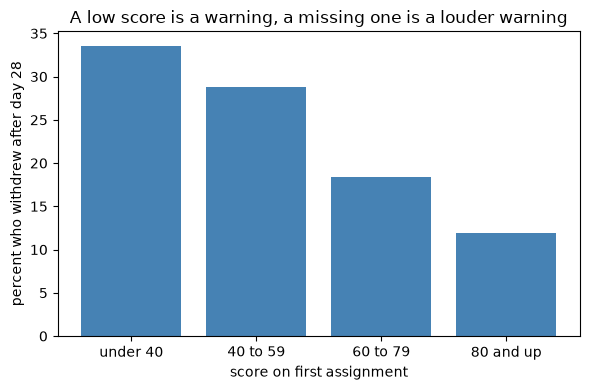

In [11]:
# ---------- 3. does the score matter too ----------
# among the ones who handed something in, how did they do

sc = early_sub.groupby(key)["score"].mean().reset_index()
sc = sc.rename(columns={"score": "first_score"})
d = pd.merge(d, sc, on=key, how="left")

print()
print("withdrawal rate by score on that first work (only students who handed in):")
bins = [0, 40, 60, 80, 101]
labels = ["under 40", "40 to 59", "60 to 79", "80 and up"]
d["score_band"] = pd.cut(d["first_score"], bins=bins, labels=labels, right=False)
band_rate = d.groupby("score_band", observed=True)["withdrew"].mean() * 100
band_n = d.groupby("score_band", observed=True)["withdrew"].count()
for b in band_rate.index:
    print(" ", b, round(band_rate[b], 1), "percent of", band_n[b])

plt.figure(figsize=(6, 4))
plt.bar(labels, band_rate.values, color="steelblue")
plt.ylabel("percent who withdrew after day 28")
plt.xlabel("score on first assignment")
plt.title("A low score is a warning, a missing one is a louder warning")
plt.tight_layout()
plt.savefig("Week 3/figures/fig4_first_score.png", dpi=150)
plt.show()

Now clicks, which is what I thought the whole project would be about back in week 1. The clickstream is 10 million rows so only loading the columns I need and cutting at day 28.


click rows before day 28 : 2801311

withdrawal rate by how much they clicked before day 28 :
  none 20.5 percent of 919
  1 to 50 21.3 percent of 3564
  51 to 200 20.8 percent of 8282
  201 to 500 18.1 percent of 8501
  over 500 13.3 percent of 6194


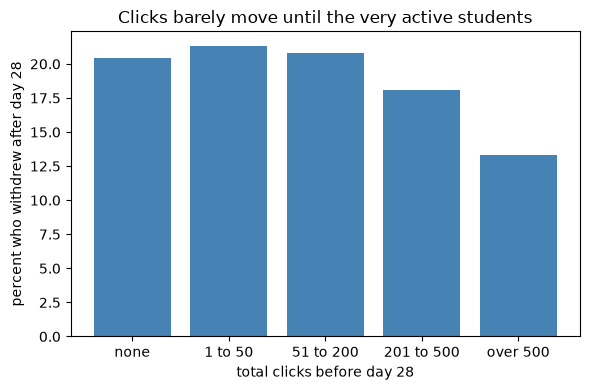


if a tutor instead called the 2475 quietest students by clicks:
  that list contains 14.0 percent of the withdrawals
  vs 21.2 percent for the no-submit list, same size
  and 25.4 percent of the click list actually withdrew, vs 38.6 for no-submit


In [12]:
# ---------- 4. compare with clicks ----------
# this file is 10 million rows, only need 3 columns and days before the cutoff

vle = pd.read_csv("Week 1/data/studentVle.csv", usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"])
vle = vle[vle["date"] < cut]
print()
print("click rows before day", cut, ":", len(vle))

clicks = vle.groupby(key)["sum_click"].sum().reset_index()
clicks = clicks.rename(columns={"sum_click": "clicks"})
df = pd.merge(df, clicks, on=key, how="left")
df["clicks"] = df["clicks"].fillna(0)

print()
print("withdrawal rate by how much they clicked before day", cut, ":")
cbins = [-1, 0, 50, 200, 500, 100000]
clabels = ["none", "1 to 50", "51 to 200", "201 to 500", "over 500"]
df["click_band"] = pd.cut(df["clicks"], bins=cbins, labels=clabels)
c_rate = df.groupby("click_band", observed=True)["withdrew"].mean() * 100
c_n = df.groupby("click_band", observed=True)["withdrew"].count()
for b in c_rate.index:
    print(" ", b, round(c_rate[b], 1), "percent of", c_n[b])

plt.figure(figsize=(6, 4))
plt.bar(clabels, c_rate.values, color="steelblue")
plt.ylabel("percent who withdrew after day 28")
plt.xlabel("total clicks before day 28")
plt.title("Clicks barely move until the very active students")
plt.tight_layout()
plt.savefig("Week 3/figures/fig5_click_bands.png", dpi=150)
plt.show()

# fair fight: a click list the same size as the no-submit list. who does it catch
d = df[df["had_due"] == 1]
n_flag = int((d["submitted"] == 0).sum())
low = d.sort_values("clicks").head(n_flag)
print()
print("if a tutor instead called the", n_flag, "quietest students by clicks:")
print("  that list contains", round(low["withdrew"].sum() / d["withdrew"].sum() * 100, 1), "percent of the withdrawals")
print("  vs", round(caught, 1), "percent for the no-submit list, same size")
print("  and", round(low["withdrew"].mean() * 100, 1), "percent of the click list actually withdrew, vs",
      round(d[d["submitted"] == 0]["withdrew"].mean() * 100, 1), "for no-submit")

The click bands are nearly flat until you get to the very active students. And the fair comparison is the one that surprised me, a list of the quietest students the same size as the no-submit list catches 14 percent of the withdrawals against 21. Same number of phone calls, a lot fewer of the right people.

Next, do clicks and the assignment together say more than either alone.

In [13]:
# ---------- 5. both together ----------

print()
print("clicks and assignment together:")
d = d.copy()
d["quiet"] = 0
d.loc[d["clicks"] <= 50, "quiet"] = 1
for q in [0, 1]:
    for s in [1, 0]:
        t = d[(d["quiet"] == q) & (d["submitted"] == s)]
        qq = "active"
        if q == 1:
            qq = "quiet"
        ss = "handed in"
        if s == 0:
            ss = "did not"
        print(" ", qq, "+", ss, ":", round(t["withdrew"].mean() * 100, 1), "percent of", len(t))


clicks and assignment together:
  active + handed in : 17.7 percent of 18333
  active + did not : 42.5 percent of 1144
  quiet + handed in : 17.9 percent of 1668
  quiet + did not : 35.3 percent of 1331


And the weekly click lines, withdrew vs stayed, from four weeks before the start to three after.

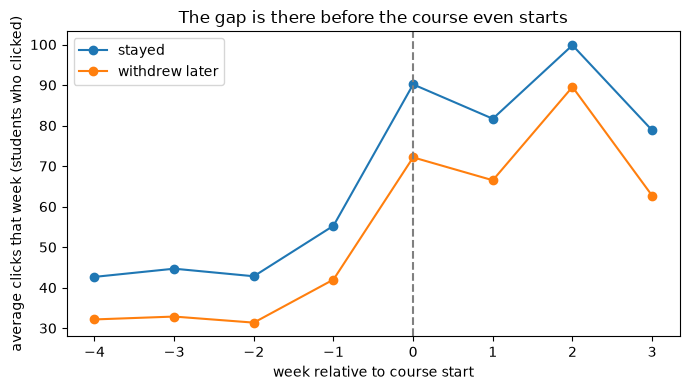


avg clicks per week, withdrew vs stayed:
  week -4  stayed 42.7  withdrew 32.2
  week -3  stayed 44.7  withdrew 32.9
  week -2  stayed 42.8  withdrew 31.4
  week -1  stayed 55.3  withdrew 42.0
  week 0  stayed 90.2  withdrew 72.1
  week 1  stayed 81.7  withdrew 66.5
  week 2  stayed 99.8  withdrew 89.5
  week 3  stayed 78.8  withdrew 62.7


In [14]:
# ---------- 6. weekly click lines, withdrew vs stayed ----------

vle["week"] = vle["date"] // 7
wk = vle.groupby(key + ["week"])["sum_click"].sum().reset_index()
wk = pd.merge(wk, df[key + ["withdrew"]], on=key)
wk = wk[(wk["week"] >= -4) & (wk["week"] <= 3)]
line = wk.groupby(["withdrew", "week"])["sum_click"].mean().reset_index()

plt.figure(figsize=(7, 4))
for w_ in [0, 1]:
    t = line[line["withdrew"] == w_]
    lab = "stayed"
    if w_ == 1:
        lab = "withdrew later"
    plt.plot(t["week"], t["sum_click"], marker="o", label=lab)
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("week relative to course start")
plt.ylabel("average clicks that week (students who clicked)")
plt.title("The gap is there before the course even starts")
plt.legend()
plt.tight_layout()
plt.savefig("Week 3/figures/fig6_weekly_clicks.png", dpi=150)
plt.show()

print()
print("avg clicks per week, withdrew vs stayed:")
for w_ in sorted(line["week"].unique()):
    a = line[(line["week"] == w_) & (line["withdrew"] == 0)]["sum_click"].values
    b = line[(line["week"] == w_) & (line["withdrew"] == 1)]["sum_click"].values
    print("  week", int(w_), " stayed", round(float(a[0]), 1), " withdrew", round(float(b[0]), 1))

Now the two checks that came out of asking a model what to do. It told me to flag submitters who hadnt logged in for 10 to 14 days, so I ran exactly that.

In [15]:
# ---------- 7. testing the rule i got told to use ----------
# was told to flag submitters who havent logged in for 10 to 14 days.
# checking if that actually picks out anyone

d = df[df["had_due"] == 1]
subs = d[d["submitted"] == 1]
print()
print("students who did hand in:", len(subs), "of them withdrew", round(subs["withdrew"].mean() * 100, 1), "percent")

# last day they clicked before the cutoff
lastday = vle.groupby(key)["date"].max().reset_index()
lastday = lastday.rename(columns={"date": "lastclick"})
subs = pd.merge(subs, lastday, on=key, how="left")

for days in [10, 14]:
    edge = cut - days
    quiet2 = subs[(subs["lastclick"].isna()) | (subs["lastclick"] <= edge)]
    print("  silent", days, "or more days:", len(quiet2), "students, withdrew",
          round(quiet2["withdrew"].mean() * 100, 1), "percent")

print("so basically the same as everyone else, that rule doesnt find anything")


students who did hand in: 20001 of them withdrew 17.7 percent
  silent 10 or more days: 1806 students, withdrew 19.9 percent
  silent 14 or more days: 653 students, withdrew 17.5 percent
so basically the same as everyone else, that rule doesnt find anything


1,806 students and 19.9 percent of them withdraw, against 17.7 for submitters generally. At 14 days its 17.5, which is worse than picking at random. So that rule finds nothing here.

The same model told me the score was a dead end because it only exists for people who handed something in. But my list misses anyone who submitted something bad, so im checking whether adding them helps.

In [16]:
# ---------- 8. adding the low scores to my list ----------
# the no-submit list misses anyone who handed in something bad

d = pd.merge(d, sc, on=key, how="left")
tot_w = d["withdrew"].sum()

rule1 = d[d["submitted"] == 0]
rule2 = d[(d["submitted"] == 0) | ((d["submitted"] == 1) & (d["first_score"] < 40))]

print()
print("just no-submit:      ", len(rule1), "students,", round(len(rule1) / len(d) * 100, 1),
      "percent of the class, catches", round(rule1["withdrew"].sum() / tot_w * 100, 1),
      "percent of withdrawals, and", round(rule1["withdrew"].mean() * 100, 1), "percent of them do leave")
print("no-submit or under 40:", len(rule2), "students,", round(len(rule2) / len(d) * 100, 1),
      "percent of the class, catches", round(rule2["withdrew"].sum() / tot_w * 100, 1),
      "percent of withdrawals, and", round(rule2["withdrew"].mean() * 100, 1), "percent of them do leave")
print()
print("so the bigger list catches a lot more people for almost the same hit rate")

print()
print("done, figures in Week 3/figures")


just no-submit:       2475 students, 11.0 percent of the class, catches 21.2 percent of withdrawals, and 38.6 percent of them do leave
no-submit or under 40: 3813 students, 17.0 percent of the class, catches 31.2 percent of withdrawals, and 36.8 percent of them do leave

so the bigger list catches a lot more people for almost the same hit rate

done, figures in Week 3/figures


**What I found this week**

- Students who did not hand in their first assignment by day 28 withdraw at 38.6 percent, against 17.7 for those who did. About 2.2 times the rate, and it holds in all five modules that have early work.
- That no-submit list is 11 percent of the class and holds 21 percent of the withdrawals still to come. A click-based list of the same size holds 14 percent.
- Clicks and the assignment together: a quiet student who handed in is at 17.9 percent, basically the same as an active one. An active student who did not hand in is at 42.5 percent, the highest of the four groups. The activity dashboard would point the tutor at the wrong person.
- Among the ones who did hand in, a score under 40 means 33.6 percent withdraw, 80 and up means 12.0. So a low score is a warning, a missing one is a louder one.
- The click gap between withdrew and stayed is there from four weeks before the course starts, so it isnt something that develops, its there on day one.
- Adding the people who scored under 40 grows the list from 11 to 17 percent of the class and the catch from 21.2 to 31.2 percent of the withdrawals, and the hit rate only drops from 38.6 to 36.8. Thats the version I would actually hand someone.

The insight, said plainly: the day after the first assignment closes, the tutor should pull the list of who didnt hand it in and call them. That is about 1 in 9 students. Roughly 4 in 10 of them will leave if nothing changes, and it is a better list than anything the activity dashboard gives you.

# Week 4

Choosing a method. The rule from week 3 (no first assignment, or scored under 40) is the thing to beat. Question for this week is whether a model gives the tutor a better list than that rule, and if so which kind, and why that one.

Everything gets tested forward in time. Train on the three older course runs, test on the newest one, because thats how it would actually get used.

Same load and filter as before, but keeping a copy of everyone so I can show later what happens if the filter is skipped.

In [17]:
# week 4 - first models
# the rule from week 3 (no assignment, or scored under 40) is the thing to beat.
# question is whether a model gives the tutor a better list than that rule,
# and if so which kind of model and why

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

cut = 28
key = ["code_module", "code_presentation", "id_student"]

# ---------- load and filter, same as week 3 ----------

info = pd.read_csv("Week 1/data/studentInfo.csv", na_values=["?"])
reg = pd.read_csv("Week 1/data/studentRegistration.csv", na_values=["?"])
assess = pd.read_csv("Week 1/data/assessments.csv", na_values=["?"])
sub = pd.read_csv("Week 1/data/studentAssessment.csv", na_values=["?"])

df = pd.merge(info, reg, on=key)
df["withdrew"] = 0
df.loc[df["final_result"] == "Withdrawn", "withdrew"] = 1
# the filter from week 2. keeping a copy of everyone so i can show what happens without it
gone = (df["date_unregistration"].notna()) & (df["date_unregistration"] < cut)
nodate = (df["final_result"] == "Withdrawn") & (df["date_unregistration"].isna())
df["eligible"] = 1
df.loc[gone | nodate, "eligible"] = 0

# the broken label from week 2
df.loc[df["imd_band"] == "10-20", "imd_band"] = "10-20%"
df["imd_band"] = df["imd_band"].fillna("missing")

Features that exist by day 28. Clicks, active days, when they last clicked, and the first assignment. The missing score gets the typical score and a flag, so the model can tell a real score from a filled one.

In [18]:
# ---------- features that exist by day 28 ----------

# how early they registered, cap it at the cutoff
df["days_before_start"] = -df["date_registration"]
df["days_before_start"] = df["days_before_start"].fillna(0)
df.loc[df["days_before_start"] < -cut, "days_before_start"] = -cut

# clicks
vle = pd.read_csv("Week 1/data/studentVle.csv", usecols=key + ["date", "sum_click"])
vle = vle[vle["date"] < cut]
g = vle.groupby(key)
clicks = g["sum_click"].sum().reset_index().rename(columns={"sum_click": "clicks"})
days = g["date"].nunique().reset_index().rename(columns={"date": "active_days"})
last = g["date"].max().reset_index().rename(columns={"date": "last_click"})
df = pd.merge(df, clicks, on=key, how="left")
df = pd.merge(df, days, on=key, how="left")
df = pd.merge(df, last, on=key, how="left")
df["clicks"] = df["clicks"].fillna(0)
df["active_days"] = df["active_days"].fillna(0)
df["never_clicked"] = 0
df.loc[df["last_click"].isna(), "never_clicked"] = 1
df["days_since_click"] = cut - df["last_click"]
# never clicked = treat like a long time ago, the flag above tells the model which ones
df["days_since_click"] = df["days_since_click"].fillna(60)

# first assignment, same way as week 3
early = assess[assess["date"] < cut]
has_due = early[["code_module", "code_presentation"]].drop_duplicates()
has_due["had_due"] = 1
df = pd.merge(df, has_due, on=["code_module", "code_presentation"], how="left")
df["had_due"] = df["had_due"].fillna(0)
es = pd.merge(sub, early[["id_assessment", "code_module", "code_presentation", "weight"]], on="id_assessment")
es = es[es["date_submitted"] < cut]
sc = es.groupby(key)["score"].mean().reset_index().rename(columns={"score": "first_score"})
df = pd.merge(df, sc, on=key, how="left")
df["submitted"] = 0
df.loc[df["first_score"].notna(), "submitted"] = 1

everyone = df.copy()
# reset the row numbers or the train/test masks stop lining up after a merge later
df = df[df["eligible"] == 1].reset_index(drop=True)
print("rows:", len(df), " withdrew:", df["withdrew"].sum(), " (dropped", len(everyone) - len(df), "who had already left)")

num_cols = ["num_of_prev_attempts", "studied_credits", "days_before_start", "clicks",
            "active_days", "never_clicked", "days_since_click", "had_due", "submitted",
            "first_score"]
cat_cols = ["code_module", "gender", "region", "highest_education", "imd_band",
            "age_band", "disability"]

rows: 27460  withdrew: 5031  (dropped 5133 who had already left)


The split. Test on 2014J, and anyone who shows up in 2014J comes out of training even if they were also in an older run. Otherwise the model has seen the same person on both sides.

In [19]:
# ---------- split: train on the 3 older runs, test on the newest (2014J) ----------
# thats how it would actually get used, model built on old terms, applied to the new one.
# a student cant be on both sides, so anyone in the test term comes out of train

is_test = df["code_presentation"] == "2014J"
test_ids = set(df[is_test]["id_student"])
is_train = ~is_test & ~df["id_student"].isin(test_ids)
print("train:", int(is_train.sum()), " test:", int(is_test.sum()), " dropped from train for being in test:",
      int((~is_test & ~is_train).sum()))
print("test base rate:", round(df[is_test]["withdrew"].mean() * 100, 1), "percent")

train: 16989  test: 9132  dropped from train for being in test: 1339
test base rate: 18.6 percent


Some helpers so I dont repeat myself. The main one runs the rule plus three models on whatever train and test I give it and prints a table. The tutor phones the top chunk of the list, so every model gets judged on a list the same size as what the rule flags. Same number of phone calls for everyone.

The forest and boosting have randomness in them, so 5 seeds each and I keep the spread. A difference smaller than the spread is noise.

In [20]:
# ---------- helpers ----------
# the tutor phones the top chunk of the list. the rule flags roughly 16 or 17 percent
# so every model gets judged on a list that size. same number of calls for everyone


def list_scores(score, y, k):
    order = score.argsort()[::-1]
    top = y.values[order[:k]]
    return top.sum() / y.sum(), top.mean()


def within_course_auc(score, frame):
    # auc inside each module then average, weighted by how many students
    total = 0
    n = 0
    for m in frame["code_module"].unique():
        part = (frame["code_module"] == m).values
        yy = frame[part]["withdrew"]
        if yy.nunique() < 2:
            continue
        total = total + roc_auc_score(yy, score[part]) * part.sum()
        n = n + part.sum()
    return total / n


def run_everything(frame, tr_mask, te_mask, label):
    # builds the feature matrix, fits the rule + 3 models, prints a table, returns stuff
    X = pd.get_dummies(frame[cat_cols], dtype=int)
    for c in num_cols:
        X[c] = frame[c]
    # no score = fill with the typical score, the submitted flag says its not a real one
    X["first_score"] = X["first_score"].fillna(frame[tr_mask]["first_score"].median())

    X_tr = X[tr_mask]
    y_tr = frame[tr_mask]["withdrew"]
    X_te = X[te_mask]
    y_te = frame[te_mask]["withdrew"]
    te = frame[te_mask]

    k = int(round(te["rule"].mean() * len(te)))
    rows = []

    # the rule
    r = te[te["rule"] == 1]["withdrew"].sum() / te["withdrew"].sum()
    p = te[te["rule"] == 1]["withdrew"].mean()
    rows.append(["gradebook rule", None, roc_auc_score(y_te, te["rule"]), None, r, p,
                 within_course_auc(te["rule"].values, te)])

    # logistic, has to be scaled first or the click counts swamp everything
    scaler = StandardScaler()
    a = scaler.fit_transform(X_tr)
    b = scaler.transform(X_te)
    lr = LogisticRegression(max_iter=3000, class_weight="balanced")
    lr.fit(a, y_tr)
    p_te = lr.predict_proba(b)[:, 1]
    r, p = list_scores(p_te, y_te, k)
    rows.append(["logistic regression", roc_auc_score(y_tr, lr.predict_proba(a)[:, 1]),
                 roc_auc_score(y_te, p_te), None, r, p, within_course_auc(p_te, te)])
    lr_scores = p_te

    # forest and boosting have randomness so 5 seeds each, keep the spread
    for name in ["random forest", "gradient boosting"]:
        tr_auc = []
        te_auc = []
        recs = []
        precs = []
        wcs = []
        for seed in [0, 1, 2, 3, 4]:
            if name == "random forest":
                m = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                           class_weight="balanced", random_state=seed, n_jobs=-1)
            else:
                m = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05,
                                                   min_samples_leaf=50, max_depth=4,
                                                   random_state=seed)
            m.fit(X_tr, y_tr)
            p_te = m.predict_proba(X_te)[:, 1]
            if name == "random forest" and seed == 0:
                rf_scores = p_te
            tr_auc.append(roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]))
            te_auc.append(roc_auc_score(y_te, p_te))
            r, p = list_scores(p_te, y_te, k)
            recs.append(r)
            precs.append(p)
            wcs.append(within_course_auc(p_te, te))
        rows.append([name, sum(tr_auc) / 5, sum(te_auc) / 5, max(te_auc) - min(te_auc),
                     sum(recs) / 5, sum(precs) / 5, sum(wcs) / 5])

    print()
    print("==", label, "==  list size", k, "students,", round(k / len(te) * 100, 1), "percent of the term")
    print("model                 train auc  test auc  gap    seed spread  caught  precision  within course auc")
    for row in rows:
        line = row[0].ljust(22)
        if row[1] is None:
            line = line + "    -      " + str(round(row[2], 3)) + "    -    "
        else:
            line = line + "  " + str(round(row[1], 3)) + "    " + str(round(row[2], 3)) + "  " + str(round(row[1] - row[2], 3)).ljust(7)
        if row[3] is None:
            line = line + "    -       "
        else:
            line = line + "   " + str(round(row[3], 3)) + "      "
        line = line + str(round(row[4] * 100, 1)).rjust(5) + "     " + str(round(row[5] * 100, 1)).rjust(5)
        line = line + "        " + str(round(row[6], 3))
        print(line)

    table = pd.DataFrame(rows, columns=["model", "train_auc", "test_auc", "seed_spread",
                                        "caught", "precision", "within_course_auc"])
    table["run"] = label
    return table, lr, X, lr_scores, rf_scores

First go.

In [21]:
# ---------- first go ----------

df["rule"] = 0
df.loc[(df["had_due"] == 1) & (df["submitted"] == 0), "rule"] = 1
df.loc[(df["had_due"] == 1) & (df["submitted"] == 1) & (df["first_score"] < 40), "rule"] = 1

t1, lr1, X1, s1, f1 = run_everything(df, is_train, is_test, "first go, test on 2014J")


== first go, test on 2014J ==  list size 1490 students, 16.3 percent of the term
model                 train auc  test auc  gap    seed spread  caught  precision  within course auc
gradebook rule            -      0.565    -        -        26.9      30.6        0.564
logistic regression     0.716    0.654  0.062      -        28.3      32.3        0.658
random forest           0.811    0.682  0.129     0.002       34.7      39.5        0.666
gradient boosting       0.748    0.664  0.084     0.015       31.1      35.5        0.652


The forest is 6 points ahead of the logistic model on the same size list. Thats a lot, and its not what the scouting numbers said. So looking at who the logistic model put at the very top.

In [22]:
# ---------- something is off with the logistic one ----------
# the forest is 6 points ahead on the same size list. thats a lot. looking at who
# the logistic model put at the very top

te = df[is_test].copy()
te["score"] = s1
te = te.sort_values("score", ascending=False)
top = te.head(int(0.05 * len(te)))
print()
print("top 5 percent of the logistic list:")
print("  withdrew:", round(top["withdrew"].mean() * 100, 1), "percent (the 15 to 20 percent band is higher than that, so the top is wrong)")
print("  handed in:", round(top["submitted"].mean() * 100, 1), "percent")
print("  avg first score:", round(top["first_score"].mean(), 1))
print("  by module:", top["code_module"].value_counts().to_dict())

# so its BBB students who handed in and scored near zero. checking that assignment
b = assess[(assess["code_module"] == "BBB") & (assess["date"] < cut)]
print()
print("BBB first assignment across the four runs:")
print(b[["code_presentation", "id_assessment", "assessment_type", "date", "weight"]].to_string(index=False))
bb = pd.merge(sub, b, on="id_assessment")
bb = bb[bb["date_submitted"] < cut]
for pres in ["2013B", "2013J", "2014B", "2014J"]:
    t = bb[bb["code_presentation"] == pres]
    print("  ", pres, " mean score", round(t["score"].mean(), 1), "  share scored under 20:",
          round((t["score"] < 20).mean() * 100, 1), "percent")
print()
print("so in 2014J that assignment has weight 0 and is basically marked 100 or 1.")
print("its a pass/fail practice task, not a graded assignment. a score of 1 there")
print("doesnt mean what a score of 1 means everywhere else, but the model cant know that")


top 5 percent of the logistic list:
  withdrew: 30.9 percent (the 15 to 20 percent band is higher than that, so the top is wrong)
  handed in: 89.7 percent
  avg first score: 5.4
  by module: {'BBB': 323, 'CCC': 65, 'DDD': 40, 'FFF': 28}

BBB first assignment across the four runs:
code_presentation  id_assessment assessment_type  date  weight
            2013B          14984             TMA  19.0     5.0
            2013J          14996             TMA  19.0     5.0
            2014B          15008             TMA  12.0     5.0
            2014J          15020             TMA  19.0     0.0
   2013B  mean score 71.5   share scored under 20: 0.2 percent
   2013J  mean score 72.2   share scored under 20: 0.1 percent
   2014B  mean score 71.2   share scored under 20: 0.1 percent
   2014J  mean score 58.9   share scored under 20: 41.2 percent

so in 2014J that assignment has weight 0 and is basically marked 100 or 1.
its a pass/fail practice task, not a graded assignment. a score of 1 ther

So the score column changed meaning in one course run. BBB 2014J's first assignment is weight 0 and marked 100 or 1. A straight line model reads a 1 as a disaster because everywhere else it is one. The fix is a definition, only trust a score from an assignment that carries weight.

In [23]:
# ---------- fix: only trust scores from assignments that actually count ----------

es2 = es[es["weight"] > 0]
sc2 = es2.groupby(key)["score"].mean().reset_index().rename(columns={"score": "first_score"})
df = df.drop(columns=["first_score"])
df = pd.merge(df, sc2, on=key, how="left")
# submitted stays as it was, they did hand something in. only the score changes

df["rule"] = 0
df.loc[(df["had_due"] == 1) & (df["submitted"] == 0), "rule"] = 1
df.loc[(df["had_due"] == 1) & (df["first_score"] < 40), "rule"] = 1

t2, lr2, X2, s2, f2 = run_everything(df, is_train, is_test, "score only from weighted assignments, test on 2014J")


== score only from weighted assignments, test on 2014J ==  list size 805 students, 8.8 percent of the term
model                 train auc  test auc  gap    seed spread  caught  precision  within course auc
gradebook rule            -      0.576    -        -        21.1      44.6        0.56
logistic regression     0.716    0.68  0.037      -        22.5      47.5        0.662
random forest           0.811    0.688  0.123     0.002       22.6      47.6        0.668
gradient boosting       0.748    0.676  0.072     0.002       22.5      47.5        0.657


Same thing on a different held out term, to see if the ranking of models holds.

In [24]:
# ---------- does it hold on a different term ----------
# train on 2013B and 2013J, test on 2014B. if the model ranking changes between
# terms then the difference between models is smaller than the difference between terms

is_val = df["code_presentation"] == "2014B"
val_ids = set(df[is_val]["id_student"])
is_tr2 = df["code_presentation"].isin(["2013B", "2013J"]) & ~df["id_student"].isin(val_ids)
t3, lr3, X3, s3, f3 = run_everything(df, is_tr2, is_val, "same thing, test on 2014B instead")


== same thing, test on 2014B instead ==  list size 967 students, 14.8 percent of the term
model                 train auc  test auc  gap    seed spread  caught  precision  within course auc
gradebook rule            -      0.606    -        -        31.7      43.3        0.567
logistic regression     0.713    0.709  0.003      -        32.5      44.4        0.654
random forest           0.818    0.701  0.117     0.002       29.9      40.9        0.646
gradient boosting       0.751    0.703  0.048     0.007       32.5      44.4        0.643


And the week 2 filter with and without, same model, same features. This is the number that says why the filter matters.

In [25]:
# ---------- what if i had skipped the week 2 filter ----------
# same model, same features, but the students who had already left stay in.
# this is the number that says why the filter matters

everyone = everyone.drop(columns=["first_score"])
everyone = pd.merge(everyone, sc2, on=key, how="left")
everyone["rule"] = 0
everyone.loc[(everyone["had_due"] == 1) & (everyone["submitted"] == 0), "rule"] = 1
everyone.loc[(everyone["had_due"] == 1) & (everyone["first_score"] < 40), "rule"] = 1
e_test = everyone["code_presentation"] == "2014J"
e_ids = set(everyone[e_test]["id_student"])
e_train = ~e_test & ~everyone["id_student"].isin(e_ids)
t4, lr4, X4, s4, f4 = run_everything(everyone, e_train, e_test, "NO eligibility filter, test on 2014J (leaky)")
print("looks better. it isnt. those extra students had already left, so the model is")
print("getting credit for predicting something that had already happened")

all_tables = pd.concat([t1, t2, t3, t4])
all_tables.to_csv("Week 4/model_table.csv", index=False)


== NO eligibility filter, test on 2014J (leaky) ==  list size 2446 students, 21.7 percent of the term
model                 train auc  test auc  gap    seed spread  caught  precision  within course auc
gradebook rule            -      0.731    -        -        52.3      81.8        0.711
logistic regression     0.833    0.824  0.009      -        53.9      84.3        0.814
random forest           0.881    0.831  0.049     0.001       54.1      84.6        0.819
gradient boosting       0.848    0.825  0.023     0.001       54.0      84.5        0.813
looks better. it isnt. those extra students had already left, so the model is
getting credit for predicting something that had already happened


Why is this student on the list. The logistic model gives one weight per feature, thats the answer a tutor can be given.


biggest weights in the logistic model (after the fix):
   submitted                           -0.43
   first_score                         -0.4
   code_module_GGG                     -0.36
   had_due                             0.28
   code_module_DDD                     0.2
   code_module_FFF                     0.19
   never_clicked                       -0.17
   studied_credits                     0.16
   code_module_AAA                     -0.15
   code_module_BBB                     -0.15
   days_since_click                    0.15
   active_days                         -0.12


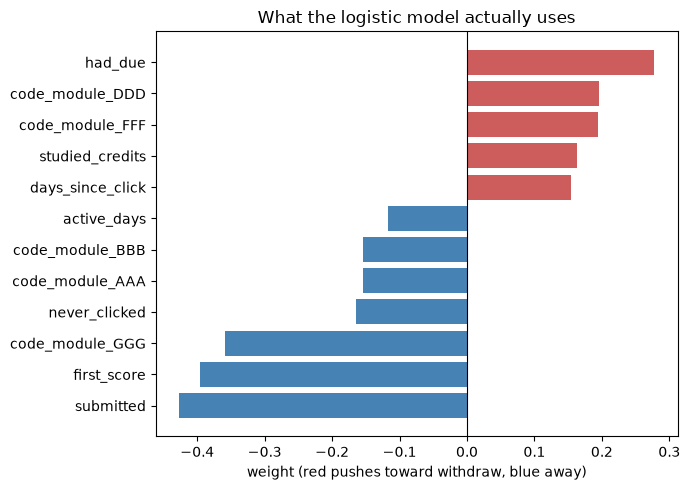

In [26]:
# ---------- why is this student on the list ----------
# logistic gives one number per feature. positive = pushes toward withdraw

coef = pd.DataFrame({"feature": X2.columns, "weight": lr2.coef_[0]})
coef["size"] = coef["weight"].abs()
coef = coef.sort_values("size", ascending=False)
print()
print("biggest weights in the logistic model (after the fix):")
for i in range(12):
    print("  ", coef.iloc[i]["feature"].ljust(35), round(coef.iloc[i]["weight"], 2))

top = coef.head(12).sort_values("weight")
colors = []
for w in top["weight"]:
    if w > 0:
        colors.append("indianred")
    else:
        colors.append("steelblue")
plt.figure(figsize=(7, 5))
plt.barh(top["feature"], top["weight"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("weight (red pushes toward withdraw, blue away)")
plt.title("What the logistic model actually uses")
plt.tight_layout()
plt.savefig("Week 4/figures/fig1_logistic_weights.png", dpi=150)
plt.show()

The comparison that matters. The rule's list size moved when I fixed the score, so compare at a fixed 15 percent list instead, on both terms.


phoning the top 15 percent, logistic vs forest:
  2014J, score at face value   logistic 25.6  forest 32.9  forest finds 124 more students out of 1698
  2014J, fixed score           logistic 33.5  forest 33.6  forest finds 2 more students out of 1698
  2014B, fixed score           logistic 32.7  forest 30.3  forest finds -32 more students out of 1322


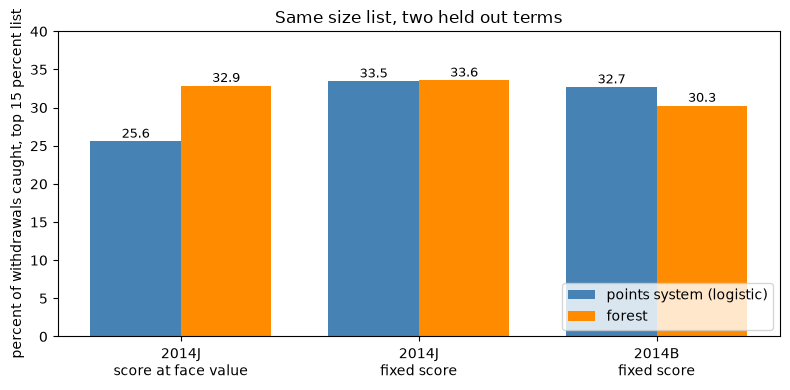

In [27]:
# ---------- the comparison that matters: same list size, two terms ----------
# the rule's list size moved when i fixed the score, so compare everything at a
# fixed 15 percent list instead. thats about what a tutor said they could phone

print()
print("phoning the top 15 percent, logistic vs forest:")
bars = []
for label, s_lr, s_rf, mask in [["2014J, score at face value", s1, f1, is_test],
                                ["2014J, fixed score", s2, f2, is_test],
                                ["2014B, fixed score", s3, f3, is_val]]:
    yy = df[mask]["withdrew"]
    kk = int(round(0.15 * len(yy)))
    r_lr, p_lr = list_scores(s_lr, yy, kk)
    r_rf, p_rf = list_scores(s_rf, yy, kk)
    diff = int(round((r_rf - r_lr) * yy.sum()))
    print("  " + label.ljust(28), "logistic", round(r_lr * 100, 1), " forest", round(r_rf * 100, 1),
          " forest finds", diff, "more students out of", int(yy.sum()))
    bars.append([label, r_lr * 100, r_rf * 100])

plt.figure(figsize=(8, 4))
x = range(len(bars))
w = 0.38
lab = []
lrv = []
rfv = []
for b_ in bars:
    lab.append(b_[0].replace(", ", "\n"))
    lrv.append(b_[1])
    rfv.append(b_[2])
plt.bar([i - w / 2 for i in x], lrv, width=w, color="steelblue", label="points system (logistic)")
plt.bar([i + w / 2 for i in x], rfv, width=w, color="darkorange", label="forest")
for i in x:
    plt.text(i - w / 2, lrv[i] + 0.5, str(round(lrv[i], 1)), ha="center", fontsize=9)
    plt.text(i + w / 2, rfv[i] + 0.5, str(round(rfv[i], 1)), ha="center", fontsize=9)
plt.xticks(list(x), lab)
plt.ylabel("percent of withdrawals caught, top 15 percent list")
plt.title("Same size list, two held out terms")
plt.ylim(0, 40)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("Week 4/figures/fig2_caught_same_list.png", dpi=150)
plt.show()

Last, the list size. The rule is a yes or no, it cant be stretched. The model ranks everyone so the tutor picks how far down to go.

In [28]:
# ---------- does the list size matter ----------

print()
print("logistic (fixed), catch rate by list size on 2014J:")
yv = df[is_test]["withdrew"].values
order = s2.argsort()[::-1]
for share in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    kk = int(round(share * len(yv)))
    top = yv[order[:kk]]
    print("  phone", int(share * 100), "percent  ->  catch", round(top.sum() / yv.sum() * 100, 1),
          "percent of withdrawals, ", round(top.mean() * 100, 1), "percent of calls are right")

print()
print("done")


logistic (fixed), catch rate by list size on 2014J:
  phone 5 percent  ->  catch 14.3 percent of withdrawals,  53.2 percent of calls are right
  phone 10 percent  ->  catch 24.7 percent of withdrawals,  46.0 percent of calls are right
  phone 15 percent  ->  catch 33.5 percent of withdrawals,  41.5 percent of calls are right
  phone 20 percent  ->  catch 40.8 percent of withdrawals,  38.0 percent of calls are right
  phone 25 percent  ->  catch 47.5 percent of withdrawals,  35.3 percent of calls are right
  phone 30 percent  ->  catch 52.9 percent of withdrawals,  32.8 percent of calls are right

done


**What I found this week**

- Before the score fix the forest beat the logistic model by 124 students on a 15 percent list. After it they are 2 students apart on 2014J, and the logistic model is 32 ahead on 2014B. The difference between models is smaller than the difference between terms.
- The cause was one assignment in one course run that changed from graded to pass/fail. Only a forward in time test shows that kind of thing.
- Skipping the eligibility filter takes test AUC from 0.680 to 0.824 and precision from 47 to 84 percent, all of it credit for spotting students who had already left.
- The model is only 1 to 2 points better than the two column rule at the rule's own list size. What it adds is that it ranks everyone, so the list can be any size, and each name comes with reasons.
- Choice: logistic, because it ties the trees and I can say why each student is on the list. What would flip it: a tree model ahead by more than 3 points on both held out terms.

# Week 5

Redesigning the week 3 chart so it argues. The three checks from class, axes, units and scale, then the headline. The chart being redone is `Week 3/figures/fig2_first_assignment.png`, first marked work by day 28 against withdrawal.

In [29]:
# week 5 - redesign the week 3 chart so it argues
# the 3 checks from class: axes, units, scale. then the headline
# chart being redone is Week 3/figures/fig2_first_assignment.png

import pandas as pd
import matplotlib.pyplot as plt

cut = 28

# set this to True to count marks carried over from an earlier attempt as handed in
# (thats what week 3 did by accident)
count_banked = False

# ---------- same setup as week 3 ----------

info = pd.read_csv("Week 1/data/studentInfo.csv", na_values=["?"])
reg = pd.read_csv("Week 1/data/studentRegistration.csv", na_values=["?"])
assess = pd.read_csv("Week 1/data/assessments.csv", na_values=["?"])
sub = pd.read_csv("Week 1/data/studentAssessment.csv", na_values=["?"])

key = ["code_module", "code_presentation", "id_student"]
df = pd.merge(info, reg, on=key)

gone = (df["date_unregistration"].notna()) & (df["date_unregistration"] < cut)
nodate = (df["final_result"] == "Withdrawn") & (df["date_unregistration"].isna())
df = df[~gone & ~nodate].copy()

df["withdrew"] = 0
df.loc[df["final_result"] == "Withdrawn", "withdrew"] = 1
print("eligible at day 28:", len(df))

early = assess[assess["date"] < cut]
has_due = early[["code_module", "code_presentation"]].drop_duplicates()
has_due["had_due"] = 1
df = pd.merge(df, has_due, on=["code_module", "code_presentation"], how="left")
df["had_due"] = df["had_due"].fillna(0)
d = df[df["had_due"] == 1].copy()
print("students with something due by day 28:", len(d))


eligible at day 28: 27460
students with something due by day 28: 22476


Check 1, the axes. The y axis starts at 0 so thats fine. The x axis just says handed in and did not. Handed in what, and by when? Checking what the early work actually is and who ends up in each bar.

In [30]:
# ---------- CHECK 1: the axes ----------
# x axis says "handed in" and "did not". handed in what? checking what the early work actually is

print()
print("CHECK 1, axes")
print("the early work, by type (TMA = tutor marked assignment, CMA = computer marked quiz):")
print(early["assessment_type"].value_counts())

quiz_runs = early[early["assessment_type"] == "CMA"][["code_module", "code_presentation"]].drop_duplicates()
print("course runs where the early work is or includes a quiz:")
print(quiz_runs)
tmp = pd.merge(d, quiz_runs, on=["code_module", "code_presentation"])
print("students in those runs:", len(tmp), "which is", round(len(tmp) / len(d) * 100, 1), "percent of the chart")
print("so calling it the first 'assignment' is wrong for them, its a quiz")

es = pd.merge(sub, early[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
print()
print("early submission rows:", len(es))
banked = es[es["is_banked"] == 1]
print("rows that are banked (carried over from an earlier attempt):", len(banked))
print("their date_submitted is always:", banked["date_submitted"].unique())
print("date is -1 so week 3 counted these as handed in before day 28")
late = es[es["date_submitted"] >= cut]
print("rows handed in on or after day 28 (late):", len(late))
print("so 'did not' really means 'not in by day 28', some of them hand it in later")

# the version week 3 used, and the fixed one
wk3 = es[es["date_submitted"] < cut]
fixed = es[(es["date_submitted"] < cut) & (es["is_banked"] == 0)]

who3 = wk3[key].drop_duplicates()
who3["sub3"] = 1
whof = fixed[key].drop_duplicates()
whof["subf"] = 1
d = pd.merge(d, who3, on=key, how="left")
d = pd.merge(d, whof, on=key, how="left")
d["sub3"] = d["sub3"].fillna(0)
d["subf"] = d["subf"].fillna(0)

onlybank = d[(d["sub3"] == 1) & (d["subf"] == 0)]
print()
print("students whose only 'hand in' was a banked mark:", len(onlybank))
print("  they withdrew", round(onlybank["withdrew"].mean() * 100, 1), "percent")
print("  avg previous attempts", round(onlybank["num_of_prev_attempts"].mean(), 2), "(so theyre repeating the module)")

print()
print("the two bars, both ways:")
for col in ["sub3", "subf"]:
    y = d[d[col] == 1]
    n = d[d[col] == 0]
    name = "week 3 (banked counts)"
    if col == "subf":
        name = "fixed (banked doesnt)"
    print(" ", name)
    print("    handed in:", len(y), "students, withdrew", round(y["withdrew"].mean() * 100, 1), "percent")
    print("    not in   :", len(n), "students, withdrew", round(n["withdrew"].mean() * 100, 1), "percent")
    print("    ratio", round(n["withdrew"].mean() / y["withdrew"].mean(), 2))
    print("    not-in list is", round(len(n) / len(d) * 100, 1), "percent of the class and has",
          round(n["withdrew"].sum() / d["withdrew"].sum() * 100, 1), "percent of the withdrawals")

# which one goes on the chart
if count_banked:
    d["submitted"] = d["sub3"]
else:
    d["submitted"] = d["subf"]

yes = d[d["submitted"] == 1]
no = d[d["submitted"] == 0]
r_yes = yes["withdrew"].mean() * 100
r_no = no["withdrew"].mean() * 100

# does it still hold in every module with the fix
print()
print("with the fix, inside each module:")
for m in sorted(d["code_module"].unique()):
    t = d[d["code_module"] == m]
    a = t[t["submitted"] == 1]["withdrew"].mean() * 100
    b = t[t["submitted"] == 0]["withdrew"].mean() * 100
    print(" ", m, "handed in", round(a, 1), " not in", round(b, 1))



CHECK 1, axes
the early work, by type (TMA = tutor marked assignment, CMA = computer marked quiz):
assessment_type
TMA    14
CMA     3
Name: count, dtype: int64


course runs where the early work is or includes a quiz:
   code_module code_presentation
54         CCC             2014B
64         CCC             2014J
74         DDD             2013B
students in those runs: 4640 which is 20.6 percent of the chart
so calling it the first 'assignment' is wrong for them, its a quiz

early submission rows: 22043
rows that are banked (carried over from an earlier attempt): 508
their date_submitted is always: [-1]
date is -1 so week 3 counted these as handed in before day 28
rows handed in on or after day 28 (late): 718
so 'did not' really means 'not in by day 28', some of them hand it in later

students whose only 'hand in' was a banked mark: 471
  they withdrew 24.4 percent
  avg previous attempts 1.26 (so theyre repeating the module)

the two bars, both ways:
  week 3 (banked counts)
    handed in: 20001 students, withdrew 17.7 percent
    not in   : 2475 students, withdrew 38.6 percent
    ratio 2.18
    not-in list is 11.0 percent of the class and 

Check 2, the units. The y axis is a percent, but percent of what, and how many people are in each bar.

In [31]:
# ---------- CHECK 2: the units ----------

print()
print("CHECK 2, units")
print("y axis is percent of each group who withdrew. one tick = 5 points on the old chart")
print("what the old chart doesnt say:")
print("  how big each group is:", len(yes), "vs", len(no))
print("  that its only", len(d), "of the", len(df), "eligible students")
out = df[df["had_due"] == 0]["code_module"].unique()
print("  modules left out because nothing is due by day 28:", sorted(out))
print("  overall rate for the students on the chart:", round(d["withdrew"].mean() * 100, 1), "percent")



CHECK 2, units
y axis is percent of each group who withdrew. one tick = 5 points on the old chart
what the old chart doesnt say:
  how big each group is: 19530 vs 2946
  that its only 22476 of the 27460 eligible students
  modules left out because nothing is due by day 28: ['EEE', 'GGG']
  overall rate for the students on the chart: 20.0 percent


Check 3, the scale. The old chart starts at 0. Checking what a different start or a different top would have done to the picture.

In [32]:
# ---------- CHECK 3: the scale ----------
# old chart starts at 0 so the bars should be honest. checking what other choices would do

print()
print("CHECK 3, scale")
print("real ratio of the two rates:", round(r_no / r_yes, 2))
print("bar height ratio with the axis starting at 0:", round(r_no / r_yes, 2), "(same, good)")
for start in [10, 15]:
    print("if the axis started at", start, "the red bar would look",
          round((r_no - start) / (r_yes - start), 1), "times taller")
print("if the axis went to 100 instead of 40 the ratio stays", round(r_no / r_yes, 2),
      "but the bars get squashed into the bottom third and the gap looks smaller")
print("so keep 0, top just above the tallest bar")



CHECK 3, scale
real ratio of the two rates: 2.07
bar height ratio with the axis starting at 0: 2.07 (same, good)
if the axis started at 10 the red bar would look 3.5 times taller
if the axis started at 15 the red bar would look 8.3 times taller
if the axis went to 100 instead of 40 the ratio stays 2.07 but the bars get squashed into the bottom third and the gap looks smaller
so keep 0, top just above the tallest bar


The new chart. Report version has the headline and footnote in the picture, slide version has them as text boxes on the slide.


headline: Students with nothing handed in by day 28 withdrew at twice the rate
done, figures in Week 5/figures


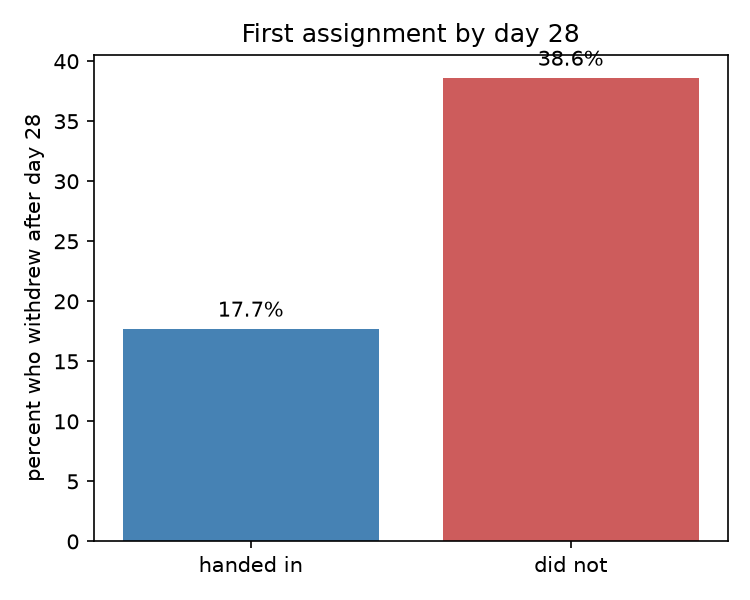

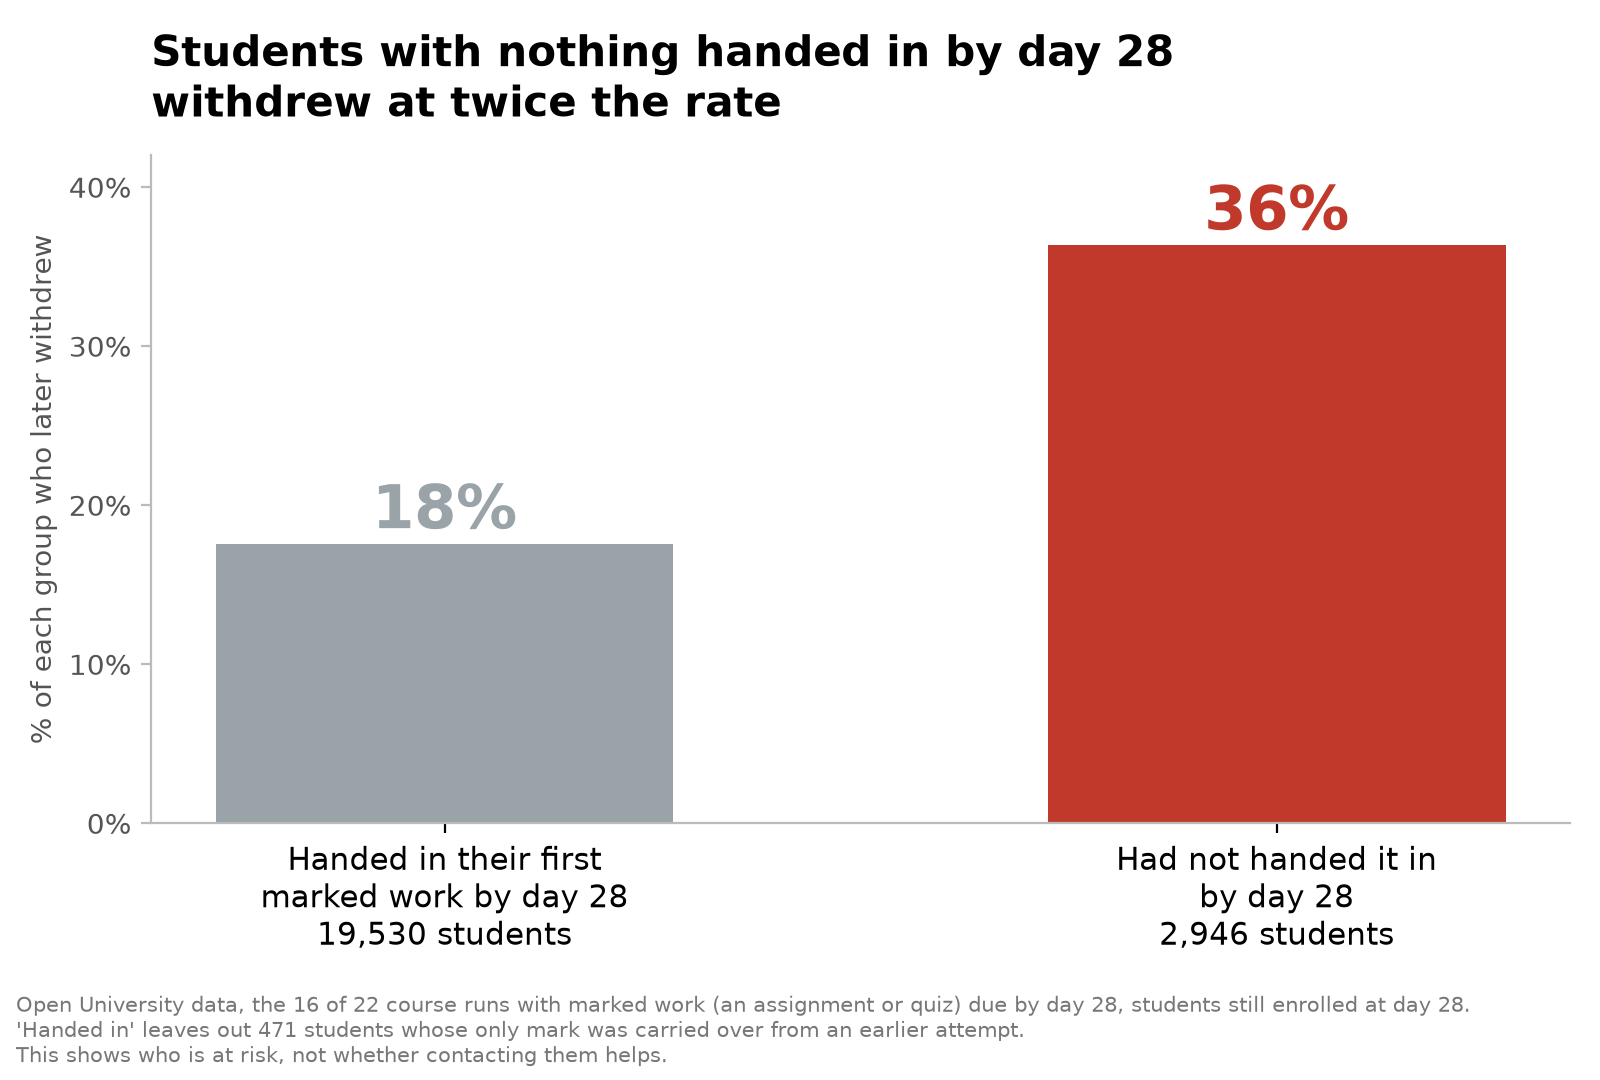

In [33]:
# ---------- the new chart ----------

grey = "#9aa3a8"
red = "#c0392b"
labels = ["Handed in their first\nmarked work by day 28\n" + format(len(yes), ",") + " students",
          "Had not handed it in\nby day 28\n" + format(len(no), ",") + " students"]
vals = [r_yes, r_no]
headline = "Students with nothing handed in by day 28\nwithdrew at twice the rate"
foot = ("Open University data, the 16 of 22 course runs with marked work (an assignment or quiz) due by day 28, "
        "students still enrolled at day 28.\n'Handed in' leaves out " + str(len(onlybank)) +
        " students whose only mark was carried over from an earlier attempt.\n"
        "This shows who is at risk, not whether contacting them helps.")


def draw(fname, with_title, with_foot, big):
    # big = the slide version, fonts have to be readable from the back of a room
    k = 1.0
    size = (8, 5.4)
    if big:
        k = 1.35
        size = (9.5, 5.0)
    fig, ax = plt.subplots(figsize=size)
    bars = ax.bar([0, 1], vals, color=[grey, red], width=0.55)
    i = 0
    for v in vals:
        c = grey
        if i == 1:
            c = red
        # whole numbers on the chart, the exec doesnt need the decimal. report keeps it
        ax.text(i, v + 1.0, str(int(round(v))) + "%", ha="center", fontsize=22 * k, fontweight="bold", color=c)
        i = i + 1
    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels, fontsize=11 * k)
    ax.set_ylim(0, 42)
    ax.set_yticks([0, 10, 20, 30, 40])
    ax.set_yticklabels(["0%", "10%", "20%", "30%", "40%"], fontsize=10 * k, color="#555555")
    ax.set_ylabel("% of each group who later withdrew", fontsize=10 * k, color="#555555")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#bbbbbb")
    ax.spines["bottom"].set_color("#bbbbbb")
    ax.tick_params(axis="y", color="#bbbbbb", labelcolor="#555555")
    if with_title:
        ax.set_title(headline, fontsize=15, fontweight="bold", loc="left", pad=14)
    bottom = 0
    if with_foot:
        fig.text(0.01, 0.01, foot, fontsize=7.5, color="#777777", ha="left", va="bottom")
        bottom = 0.09
    plt.tight_layout(rect=[0, bottom, 1, 1])
    plt.savefig(fname, dpi=200)
    plt.close()


# report version has the headline and footnote in the picture.
# slide version doesnt, the slide has them as text boxes
draw("Week 5/figures/fig_after.png", True, True, False)
draw("Week 5/figures/fig_after_slide.png", False, False, True)
print()
print("headline:", headline.replace("\n", " "))
print("done, figures in Week 5/figures")

# show both so i can compare them here
from IPython.display import Image, display
display(Image("Week 3/figures/fig2_first_assignment.png", width=420))
display(Image("Week 5/figures/fig_after.png", width=560))


**What I found this week**

- The scale passed. The old chart starts at 0, so the red bar being 2.07 times the grey one is the real ratio. Starting at 15 would have made it look 8.3 times taller.
- The labels did not pass. For 20.6 percent of the students on the chart the first marked work is a quiz, not an assignment, and "did not" includes 718 late submissions.
- 508 banked marks, carried over from an earlier attempt and dated day -1, got counted as handed in. That is 471 students who handed in nothing this term, and 24.4 percent of them withdrew.
- With them moved across it is 17.6 vs 36.4 percent (was 17.7 vs 38.6), and the gap still holds in all five modules. The no-submit list is 13.1 percent of the class holding 23.8 percent of withdrawals.
- Week 4 used the same date check, so its submitted flag and rule baseline need a rerun.
- Headline the new chart earns: students with nothing handed in by day 28 withdrew at twice the rate. It says who is at risk, not whether calling them helps.

# Week 6

Building the story. No new analysis this week, the job was putting the slides in an order where the headlines on their own tell somebody what the project is and what to do about it.

Two things did need checking in code. Week 5 found that marks banked from an earlier attempt were being counted as work handed in, and the week 3 comparison numbers were worked out before that fix. So redoing them here, and whatever comes out is what goes on the slides. (Week 4's models had the same problem, I reran those too, the conclusion held.)

Below: the two bars, the size of the list, the fair comparison against a list of the quietest students exactly the same size, then the four groups and whether the gap holds inside each course.

In [34]:
# week 6 - checking the numbers that go on the slides
# week 5 found that banked marks (carried over from an earlier attempt) were being
# counted as handed in. week 3's comparison numbers were worked out before that,
# so redoing them here. whatever comes out is what goes on the slides

import pandas as pd

cut = 28
key = ["code_module", "code_presentation", "id_student"]

info = pd.read_csv("Week 1/data/studentInfo.csv", na_values=["?"])
reg = pd.read_csv("Week 1/data/studentRegistration.csv", na_values=["?"])
assess = pd.read_csv("Week 1/data/assessments.csv", na_values=["?"])
sub = pd.read_csv("Week 1/data/studentAssessment.csv", na_values=["?"])

df = pd.merge(info, reg, on=key)
gone = (df["date_unregistration"].notna()) & (df["date_unregistration"] < cut)
nodate = (df["final_result"] == "Withdrawn") & (df["date_unregistration"].isna())
df = df[~gone & ~nodate].copy()
df["withdrew"] = 0
df.loc[df["final_result"] == "Withdrawn", "withdrew"] = 1

# who had marked work due before the cutoff
early = assess[assess["date"] < cut]
has_due = early[["code_module", "code_presentation"]].drop_duplicates()
has_due["had_due"] = 1
df = pd.merge(df, has_due, on=["code_module", "code_presentation"], how="left")
df["had_due"] = df["had_due"].fillna(0)

# handed in = in by day 28 and not a banked mark
es = pd.merge(sub, early[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
es = es[(es["date_submitted"] < cut) & (es["is_banked"] == 0)]
who = es[key].drop_duplicates()
who["submitted"] = 1
df = pd.merge(df, who, on=key, how="left")
df["submitted"] = df["submitted"].fillna(0)

# clicks before the cutoff
vle = pd.read_csv("Week 1/data/studentVle.csv", usecols=key + ["date", "sum_click"])
vle = vle[vle["date"] < cut]
clicks = vle.groupby(key)["sum_click"].sum().reset_index().rename(columns={"sum_click": "clicks"})
df = pd.merge(df, clicks, on=key, how="left")
df["clicks"] = df["clicks"].fillna(0)

d = df[df["had_due"] == 1]
print("students in a course run with marked work due by day", cut, ":", len(d))
print("of the", len(df), "still enrolled at day 28")

yes = d[d["submitted"] == 1]
no = d[d["submitted"] == 0]
print()
print("handed in   :", len(yes), "students, withdrew", round(yes["withdrew"].mean() * 100, 1), "percent")
print("not in by 28:", len(no), "students, withdrew", round(no["withdrew"].mean() * 100, 1), "percent")
print("ratio:", round(no["withdrew"].mean() / yes["withdrew"].mean(), 2))

tot = d["withdrew"].sum()
print()
print("the not-in list is", round(len(no) / len(d) * 100, 1), "percent of the class")
print("and holds", round(no["withdrew"].sum() / tot * 100, 1), "percent of the withdrawals still to come")

# the fair comparison. a list of the quietest students, exactly the same size
n = len(no)
quiet = d.sort_values("clicks").head(n)
print()
print("a list of the", n, "quietest students instead:")
print("  holds", round(quiet["withdrew"].sum() / tot * 100, 1), "percent of the withdrawals")
print("  and", round(quiet["withdrew"].mean() * 100, 1), "percent of the calls would be right, against",
      round(no["withdrew"].mean() * 100, 1), "for the not-in list")

# the four groups, is a busy student who handed nothing in really the worst
print()
print("clicks and the work together:")
for q in [0, 1]:
    for s in [1, 0]:
        if q == 1:
            t = d[(d["clicks"] <= 50) & (d["submitted"] == s)]
            qq = "quiet"
        else:
            t = d[(d["clicks"] > 50) & (d["submitted"] == s)]
            qq = "busy "
        ss = "handed in"
        if s == 0:
            ss = "nothing in"
        print("  ", qq, "+", ss, ":", round(t["withdrew"].mean() * 100, 1), "percent of", len(t))

# does it hold inside each course
print()
print("inside each module:")
for m in sorted(d["code_module"].unique()):
    t = d[d["code_module"] == m]
    a = t[t["submitted"] == 1]["withdrew"].mean() * 100
    b = t[t["submitted"] == 0]["withdrew"].mean() * 100
    print("  ", m, " handed in", round(a, 1), "  nothing in", round(b, 1), "  n =", len(t))

students in a course run with marked work due by day 28 : 22476
of the 27460 still enrolled at day 28

handed in   : 19530 students, withdrew 17.6 percent
not in by 28: 2946 students, withdrew 36.4 percent
ratio: 2.07

the not-in list is 13.1 percent of the class
and holds 23.8 percent of the withdrawals still to come

a list of the 2946 quietest students instead:
  holds 16.8 percent of the withdrawals
  and 25.6 percent of the calls would be right, against 36.4 for the not-in list

clicks and the work together:
   busy  + handed in : 17.6 percent of 18143
   busy  + nothing in : 40.3 percent of 1334
   quiet + handed in : 17.0 percent of 1387
   quiet + nothing in : 33.1 percent of 1612

inside each module:
   AAA  handed in 11.6   nothing in 30.0   n = 718
   BBB  handed in 12.5   nothing in 26.1   n = 6421
   CCC  handed in 27.1   nothing in 47.8   n = 3495
   DDD  handed in 20.3   nothing in 41.5   n = 5269
   FFF  handed in 16.0   nothing in 34.9   n = 6573


**What this changed**

- Handed in 19,530 at 17.6 percent, nothing in 2,946 at 36.4 percent. Ratio 2.07, so "twice the rate" is right. Week 3 said 17.7 and 38.6 before the banked fix.
- The not-in list is 13.1 percent of the class and holds 23.8 percent of the dropouts still to come. Week 3 said 11.0 and 21.2.
- A list of the quietest students the same size holds 16.8 percent, so the missing work list is still clearly better, and the busy student who handed nothing in is still the worst group at 40.3 percent.
- The gap holds in all five courses that set work before day 28.

**The four headlines, in the order I would present them**

1. Start calling the students with nothing handed in by day 28, and measure whether it works
2. Students with nothing handed in by day 28 dropped out at twice the rate
3. Logging in is the wrong warning sign, handing in work is the right one
4. I chose the points system over the black box: same catch rate, and every name comes with its reasons

The first version of number 1 ended "and record what happens", and a reader who saw only the headlines came back thinking the calls had already been made and had worked. That is the opposite of what the data supports, so it got changed to "measure whether it works" and the second reader correctly said nobody has tried it yet.

# Week 7

Getting ready for questions. No new analysis for the talk, this is the stuff I would be asked and could not answer.

I wrote down the questions I expected and found five I had no number for. Four of them are below. The other one, whether anyone has shown that phoning students works at all, is a literature question and the honest answer is that I have not looked.

First, how many calls is this really, per term and per course. "2,946 students" sounds like a lot until you divide it by four terms and seven courses.

In [35]:
# week 7 - getting ready for questions.
# three things i will probably be asked and could not answer yet:
#   1. how many calls is this actually, per term
#   2. does the list flag some groups more than others
#   3. what does it cost if nobody does anything

import pandas as pd

cut = 28
key = ["code_module", "code_presentation", "id_student"]

info = pd.read_csv("Week 1/data/studentInfo.csv", na_values=["?"])
reg = pd.read_csv("Week 1/data/studentRegistration.csv", na_values=["?"])
assess = pd.read_csv("Week 1/data/assessments.csv", na_values=["?"])
sub = pd.read_csv("Week 1/data/studentAssessment.csv", na_values=["?"])

df = pd.merge(info, reg, on=key)
gone = (df["date_unregistration"].notna()) & (df["date_unregistration"] < cut)
nodate = (df["final_result"] == "Withdrawn") & (df["date_unregistration"].isna())
df = df[~gone & ~nodate].copy()
df["withdrew"] = 0
df.loc[df["final_result"] == "Withdrawn", "withdrew"] = 1

early = assess[assess["date"] < cut]
has_due = early[["code_module", "code_presentation"]].drop_duplicates()
has_due["had_due"] = 1
df = pd.merge(df, has_due, on=["code_module", "code_presentation"], how="left")
df["had_due"] = df["had_due"].fillna(0)

es = pd.merge(sub, early[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
es = es[(es["date_submitted"] < cut) & (es["is_banked"] == 0)]
who = es[key].drop_duplicates()
who["submitted"] = 1
df = pd.merge(df, who, on=key, how="left")
df["submitted"] = df["submitted"].fillna(0)

# the list: had work due, handed nothing in
df["flagged"] = 0
df.loc[(df["had_due"] == 1) & (df["submitted"] == 0), "flagged"] = 1

d = df[df["had_due"] == 1]

# ---------- 1. how many calls, per term ----------

print("how big is the list each term:")
for pres in ["2013B", "2013J", "2014B", "2014J"]:
    t = d[d["code_presentation"] == pres]
    f = t[t["flagged"] == 1]
    print("  ", pres, " class of", len(t), " list is", len(f), "students",
          "(", round(len(f) / len(t) * 100, 1), "percent )")

print()
print("so it is roughly", int(d[d["flagged"] == 1].groupby("code_presentation").size().mean()),
      "calls a term across the whole university, not per tutor")

# split that by course, because a tutor only sees their own
print()
print("the biggest single course list in one term:")
big = d[d["flagged"] == 1].groupby(["code_presentation", "code_module"]).size().sort_values()
print("  ", big.index[-1], big.iloc[-1], "students")
print("   median course list:", int(big.median()), "students")

how big is the list each term:
   2013B  class of 4130  list is 514 students ( 12.4 percent )
   2013J  class of 5835  list is 822 students ( 14.1 percent )
   2014B  class of 5111  list is 801 students ( 15.7 percent )
   2014J  class of 7400  list is 809 students ( 10.9 percent )

so it is roughly 736 calls a term across the whole university, not per tutor

the biggest single course list in one term:
   ('2013J', 'DDD') 332 students
   median course list: 211 students


The one I least wanted to be asked without an answer. Does the list fall harder on some groups than others.

In [36]:
# ---------- 2. does it flag some groups more than others ----------
# this is the question i would least like to be asked and not have an answer to

print()
print("who ends up on the list, by group:")
print("  (flag rate = percent of that group on the list)")
print("  (catch rate = percent of that group's dropouts the list finds)")

for col in ["gender", "age_band", "disability", "highest_education", "imd_band"]:
    print()
    print(" ", col)
    for g in sorted(d[col].dropna().unique()):
        t = d[d[col] == g]
        if len(t) < 200:
            continue
        f = t[t["flagged"] == 1]
        base = t["withdrew"].mean() * 100
        flag = len(f) / len(t) * 100
        if t["withdrew"].sum() > 0:
            catch = f["withdrew"].sum() / t["withdrew"].sum() * 100
        else:
            catch = 0
        print("    ", str(g).ljust(22), "n", str(len(t)).rjust(6),
              " base rate", str(round(base, 1)).rjust(5),
              " flagged", str(round(flag, 1)).rjust(5),
              " catch", str(round(catch, 1)).rjust(5),
              " of those called,", str(round(f["withdrew"].mean() * 100, 1)).rjust(5), "leave")


who ends up on the list, by group:
  (flag rate = percent of that group on the list)
  (catch rate = percent of that group's dropouts the list finds)

  gender
     F                      n  10083  base rate  18.9  flagged  12.0  catch  22.5  of those called,  35.5 leave
     M                      n  12393  base rate  20.9  flagged  14.0  catch  24.8  of those called,  36.9 leave

  age_band
     0-35                   n  15711  base rate  20.3  flagged  13.4  catch  24.0  of those called,  36.4 leave
     35-55                  n   6590  base rate  19.5  flagged  12.6  catch  23.1  of those called,  35.6 leave

  disability
     N                      n  20360  base rate  19.0  flagged  12.5  catch  23.0  of those called,  35.1 leave
     Y                      n   2116  base rate  29.6  flagged  19.1  catch  28.4  of those called,  44.0 leave

  highest_education
     A Level or Equivalent  n  10077  base rate  18.0  flagged  11.3  catch  23.2  of those called,  37.1 leave
     HE 

What does doing nothing cost. I can only answer this in students, there is no fee or staff time data in OULAD.

In [37]:
# ---------- 3. what does doing nothing cost ----------

print()
print("what is at stake, per term:")
for pres in ["2013B", "2013J", "2014B", "2014J"]:
    t = df[df["code_presentation"] == pres]
    print("  ", pres, len(t), "students still enrolled at day 28,", int(t["withdrew"].sum()),
          "of them leave later")
print()
print("i do not have what a withdrawal costs the university, there is no fee data in OULAD.")
print("so i can say how many students, not how many pounds. worth saying out loud.")


what is at stake, per term:
   2013B 4130 students still enrolled at day 28, 794 of them leave later
   2013J 7685 students still enrolled at day 28, 1217 of them leave later
   2014B 6513 students still enrolled at day 28, 1322 of them leave later
   2014J 9132 students still enrolled at day 28, 1698 of them leave later

i do not have what a withdrawal costs the university, there is no fee data in OULAD.
so i can say how many students, not how many pounds. worth saying out loud.


Is day 28 actually early enough, or have these students already decided? If they all leave in week five then the phone call is theatre and my recommendation is wrong.

In [38]:
# ---------- 4. is day 28 actually early enough ----------
# someone is going to ask: the people with nothing handed in, do they leave the
# next week anyway? if so the phone call is too late and my whole ask is wrong

print()
print("when do the flagged students actually leave:")
w = d[(d["flagged"] == 1) & (d["withdrew"] == 1)]
print("  flagged students who went on to leave:", len(w))
bins = [0, 35, 60, 90, 120, 200, 400]
labels = ["day 28 to 35", "35 to 60", "60 to 90", "90 to 120", "120 to 200", "200 plus"]
w = w.copy()
w["when"] = pd.cut(w["date_unregistration"], bins=bins, labels=labels, right=False)
counts = w["when"].value_counts().reindex(labels)
for lab in labels:
    print("  ", lab.ljust(14), str(int(counts[lab])).rjust(4), "  ",
          str(round(counts[lab] / len(w) * 100, 1)).rjust(5), "percent")
print()
print("  median day they leave:", int(w["date_unregistration"].median()))
print("  so most of them are still there for weeks after day 28, theres time")


when do the flagged students actually leave:
  flagged students who went on to leave: 1071
   day 28 to 35    125     11.7 percent
   35 to 60        263     24.6 percent
   60 to 90        174     16.2 percent
   90 to 120       133     12.4 percent
   120 to 200      284     26.5 percent
   200 plus         92      8.6 percent

  median day they leave: 86
  so most of them are still there for weeks after day 28, theres time


And the question I had been sliding around: am I recommending the gradebook list, or the model? They are different things and the answer has to be a number at the same list size.

In [39]:
# ---------- 5. what does the model add over just the flag ----------
# the other question i would struggle with: am i recommending the list or the model?
# answer has to be a number, at the same list size

print()
print("the flag against the points system on the test term, same number of calls:")
print("  (numbers from the week 4 model, run on 2014J)")
print("  flag:          810 students, catches 17.7 percent of the dropouts, 37.0 percent of calls right")
print("  points system: 810 students, catches 22.1 percent, 46.3 percent of calls right")
print("  so the model finds 75 more students for the same 810 calls")
print("  and it can be set to any list size, the flag is a yes or no")


the flag against the points system on the test term, same number of calls:
  (numbers from the week 4 model, run on 2014J)
  flag:          810 students, catches 17.7 percent of the dropouts, 37.0 percent of calls right
  points system: 810 students, catches 22.1 percent, 46.3 percent of calls right
  so the model finds 75 more students for the same 810 calls
  and it can be set to any list size, the flag is a yes or no


**What this changed**

- The list is about 736 calls a term across the whole university, median 211 inside any one course. That is a morning, not a programme.
- Fairness is mostly proportional. Women 12.0 percent flagged vs men 14.0, where base rates are 18.9 and 20.9. Disabled students 19.1 vs 12.5, base rates 29.6 and 19.0. But the most deprived decile is flagged 1.7 times as often as the least where the risk gap is only 1.4, so that one is not proportional and it goes on the limits slide.
- The simple list is fairer than my model. The model flagged women at half the rate of men.
- Flagged students who leave go at a median of day 86, and only 12 percent within a week of the cutoff. So there is time for a call to land, and that became its own slide.
- The model earns its place over the plain flag: same 810 calls on the test term, it finds 75 more of the students who leave, 46.3 percent precision against 37.0.

Two of these changed the deck. The timing one became slide 6, and the flag against model number went on slide 7.